# Setup, Mean Face & Centering

## Load the data

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_olivetti_faces  # ONLY for downloading data

# return_X_y=True -> gives us (X, y) directly, already flattened
X, subject_ids = fetch_olivetti_faces(return_X_y=True)
X = np.asarray(X)                    # tells Pylance (and NumPy): this is an array
subject_ids = np.asarray(subject_ids)

print("X shape:", X.shape)                        # (400, 4096)
print("Pixel range:", X.min(), "to", X.max())     # 0.0 to 1.0
print("Subjects:", len(np.unique(subject_ids)))   # 40 people, 10 photos each

X shape: (400, 4096)
Pixel range: 0.0 to 1.0
Subjects: 40


## Peek at the raw faces

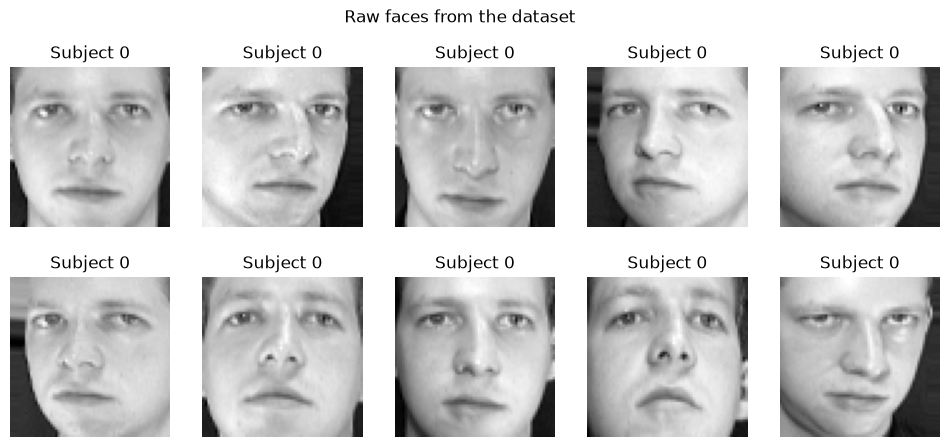

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(X[i].reshape(64, 64), cmap='gray')
    ax.set_title(f"Subject {subject_ids[i]}")
    ax.axis('off')
plt.suptitle("Raw faces from the dataset")
plt.show()

## The Mean Face

mu shape: (4096,)


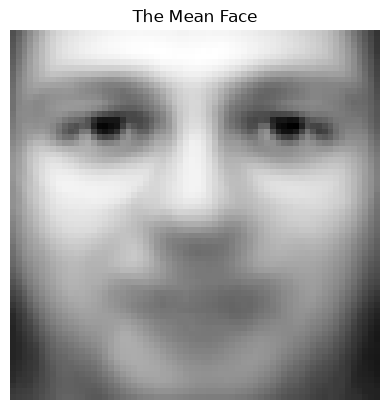

In [3]:
mu = np.mean(X, axis=0)   # type: ignore  # average down the rows -> one value per pixel
print("mu shape:", mu.shape)  # (4096,)

plt.imshow(mu.reshape(64, 64), cmap='gray')
plt.title("The Mean Face")
plt.axis('off')
plt.show()

## Center the data

In [4]:
X_c = X - mu    # broadcasting: (400,4096) - (4096,) -> subtracts mu from every row

print("X_c shape:", X_c.shape)  # (400, 4096)

# Verify: every column's mean should now be ~0
col_means = np.mean(X_c, axis=0)
print("Max |column mean|:", np.abs(col_means).max())
print("All close to zero?", np.allclose(col_means, 0, atol=1e-6))

X_c shape: (400, 4096)
Max |column mean|: 7.210672e-07
All close to zero? True


Let’s also see what a centered face looks like:

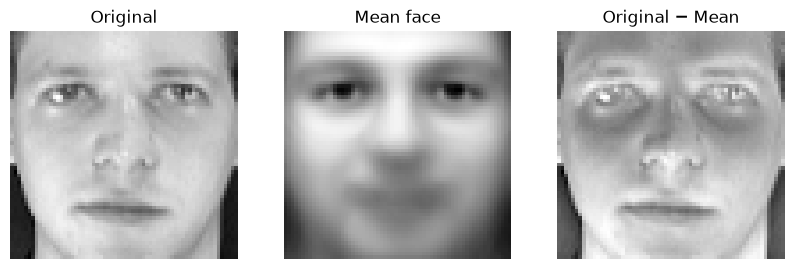

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(10, 4))
axes[0].imshow(X[0].reshape(64, 64), cmap='gray');   axes[0].set_title("Original")
axes[1].imshow(mu.reshape(64, 64), cmap='gray');     axes[1].set_title("Mean face")
axes[2].imshow(X_c[0].reshape(64, 64), cmap='gray'); axes[2].set_title("Original − Mean")
for ax in axes: ax.axis('off')
plt.show()

# Snapshot Covariance & Eigendecomposition

## Build the snapshot matrix

In [6]:
X_c = X_c.astype(np.float64)

N = X_c.shape[0]            # 400
C = (X_c @ X_c.T) / N       # snapshot (surrogate) covariance

print("C shape:", C.shape)                      # must be exactly (400, 400)
print("Is C symmetric?", np.allclose(C, C.T))   # should be True

# How much memory did we save?
big_bytes = 4096 * 4096 * 8
print(f"Big covariance would be: {big_bytes/1e6:.0f} MB")
print(f"Our C is only:           {C.nbytes/1e6:.2f} MB")
print(f"Saved: {100*(1 - C.nbytes/big_bytes):.1f}%")

C shape: (400, 400)
Is C symmetric? True
Big covariance would be: 134 MB
Our C is only:           1.28 MB
Saved: 99.0%


## Eigendecomposition

In [7]:
eigvals, eigvecs = np.linalg.eigh(C)

# Sort descending (biggest variance first)
order = np.argsort(eigvals)[::-1]
eigvals = eigvals[order]
V = eigvecs[:, order]       # columns are re-ordered to match

print("eigvals shape:", eigvals.shape)   # (400,)
print("V shape:", V.shape)               # (400, 400)
print("Top 5 eigenvalues:", eigvals[:5])
print("Last 3 eigenvalues:", eigvals[-3:])

eigvals shape: (400,)
V shape: (400, 400)
Top 5 eigenvalues: [18.79307537 11.0440827   6.2888532   3.94469764  2.84890253]
Last 3 eigenvalues: [1.58028884e-03 1.29410304e-03 9.71804916e-11]


Now two sanity checks, plus a peek at how fast importance drops:

Orthonormal? True
C v = λ v ? True


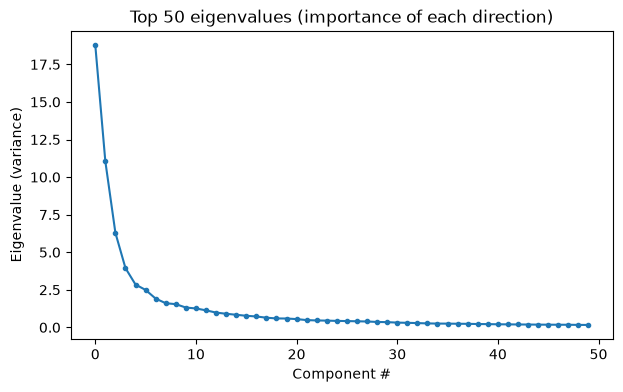

In [8]:
# 1) Are the eigenvectors orthonormal? (V^T V should be the identity)
print("Orthonormal?", np.allclose(V.T @ V, np.eye(400), atol=1e-8))

# 2) Does C v = λ v hold for the top eigenvector?
v0 = V[:, 0]
print("C v = λ v ?", np.allclose(C @ v0, eigvals[0] * v0))

# 3) Peek: how quickly does importance fall off?
plt.figure(figsize=(7, 4))
plt.plot(eigvals[:50], marker='o', ms=3)
plt.title("Top 50 eigenvalues (importance of each direction)")
plt.xlabel("Component #")
plt.ylabel("Eigenvalue (variance)")
plt.show()

# Eigenfaces Recovery

## Map back and normalize

In [9]:
# Keep the 399 meaningful directions (the last eigenvalue is ~0)
K = 399
V_k = V[:, :K]                    # (400, 399)
lam_k = eigvals[:K]               # (399,)

# Map back to pixel space: (4096, 400) @ (400, 399) -> (4096, 399)
U_raw = X_c.T @ V_k
print("U_raw shape:", U_raw.shape)

# Check our math: lengths BEFORE normalizing should be sqrt(N * lambda)
raw_norms = np.linalg.norm(U_raw, axis=0)
print("Lengths match sqrt(N*λ)?", np.allclose(raw_norms, np.sqrt(N * lam_k)))

# Normalize every column to unit length
U = U_raw / raw_norms             # broadcasting divides each column by its own norm
print("U shape:", U.shape)        # (4096, 399)

U_raw shape: (4096, 399)
Lengths match sqrt(N*λ)? True
U shape: (4096, 399)


Sanity checks

In [10]:
# 1) Every eigenface has length 1
print("All unit length?", np.allclose(np.linalg.norm(U, axis=0), 1.0))

# 2) Eigenfaces are perpendicular to each other: UᵀU = Identity
print("Orthonormal?", np.allclose(U.T @ U, np.eye(K), atol=1e-8))

# 3) Is u0 a REAL eigenvector of the big 4096x4096 covariance?
#    We test it WITHOUT building the big matrix:
#    Cov @ u = X_cᵀ (X_c u) / N
u0 = U[:, 0]
lhs = X_c.T @ (X_c @ u0) / N
print("Cov u = λ u ?", np.allclose(lhs, eigvals[0] * u0))

All unit length? True
Orthonormal? True
Cov u = λ u ? True


## See the Eigenfaces

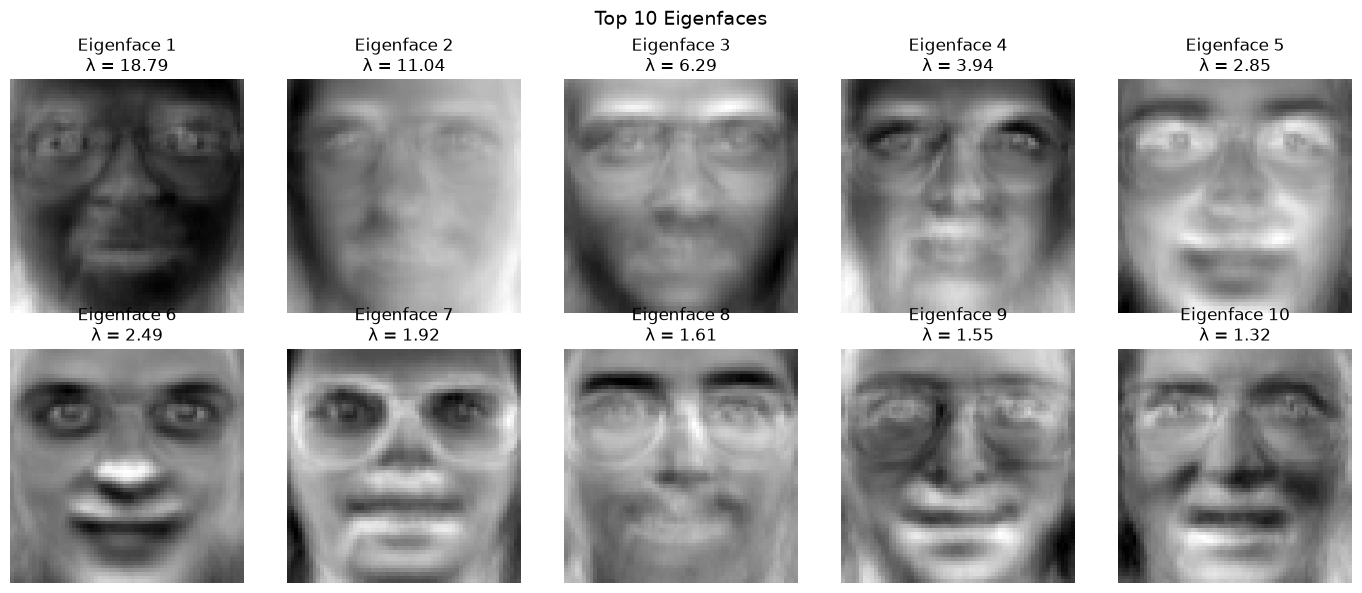

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(U[:, i].reshape(64, 64), cmap='gray')
    ax.set_title(f"Eigenface {i+1}\nλ = {eigvals[i]:.2f}")
    ax.axis('off')
plt.suptitle("Top 10 Eigenfaces", fontsize=14)
plt.tight_layout()
plt.show()

# Projection, Reconstruction & Errors

## Project & reconstruct

In [12]:
def project_and_reconstruct(X_c, U, mu, k):
    """Compress faces into k numbers, then rebuild them."""
    Uk = U[:, :k]                 # (4096, k) -> top k eigenfaces
    Z = X_c @ Uk                  # (400, k)  -> the compressed codes
    X_rec = Z @ Uk.T + mu         # (400, 4096) -> rebuilt faces
    return Z, X_rec

Z, X_rec = project_and_reconstruct(X_c, U, mu, k=30)
print("Z shape:", Z.shape)          # (400, 30)
print("X_rec shape:", X_rec.shape)  # (400, 4096)
print(f"Each face: 4096 numbers -> {Z.shape[1]} numbers "
      f"({4096 / Z.shape[1]:.0f}x smaller)")

Z shape: (400, 30)
X_rec shape: (400, 4096)
Each face: 4096 numbers -> 30 numbers (137x smaller)


## Watch a face come into focus

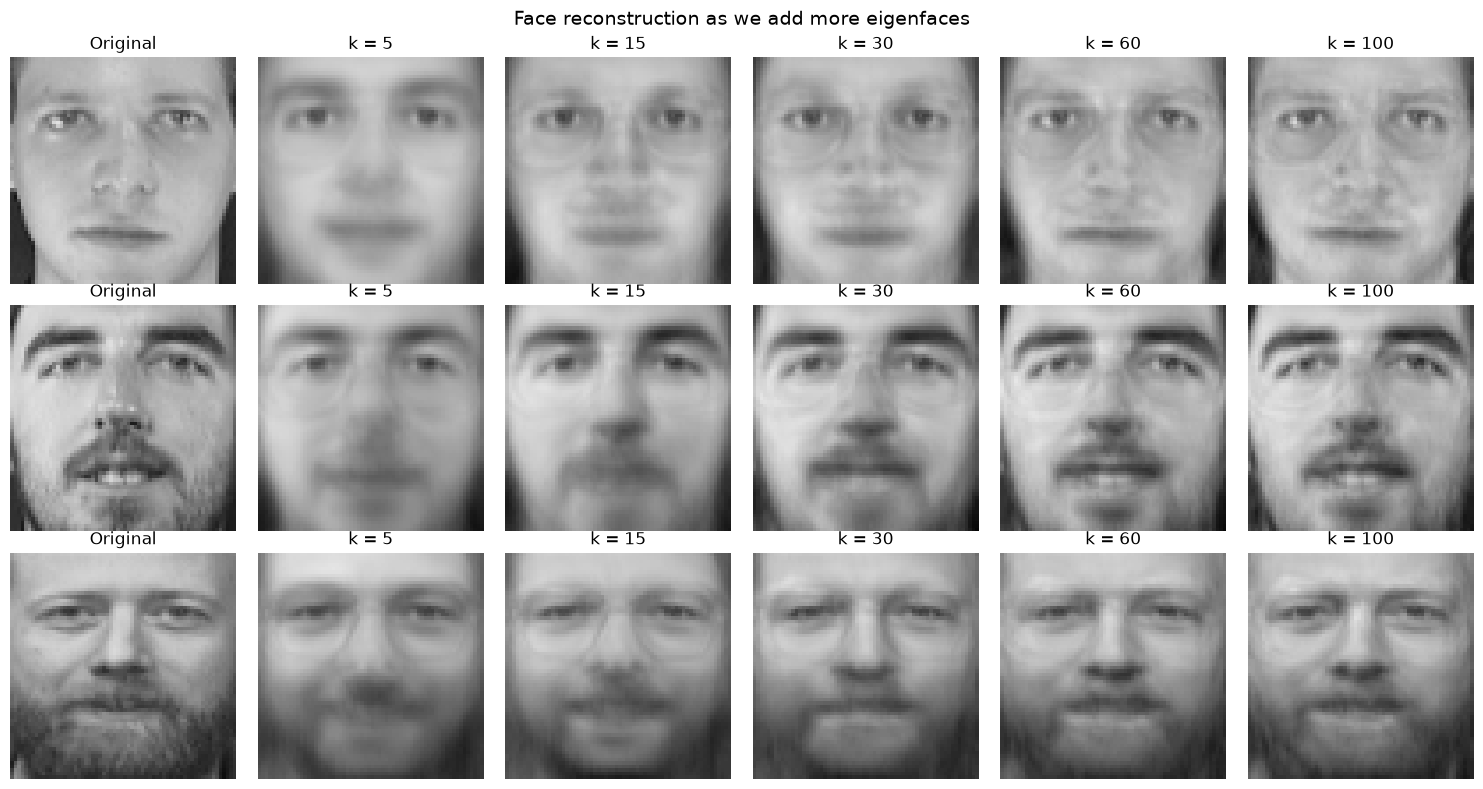

In [13]:
ranks = [5, 15, 30, 60, 100]
face_ids = [0, 100, 250]   # three different people

fig, axes = plt.subplots(len(face_ids), len(ranks) + 1, figsize=(15, 8))

for row, idx in enumerate(face_ids):
    axes[row, 0].imshow(X[idx].reshape(64, 64), cmap='gray', vmin=0, vmax=1)
    axes[row, 0].set_title("Original")
    for col, k in enumerate(ranks, start=1):
        _, rec = project_and_reconstruct(X_c[idx:idx+1], U, mu, k)
        axes[row, col].imshow(rec.reshape(64, 64), cmap='gray', vmin=0, vmax=1)
        axes[row, col].set_title(f"k = {k}")

for ax in axes.flat:
    ax.axis('off')
plt.suptitle("Face reconstruction as we add more eigenfaces", fontsize=14)
plt.tight_layout()
plt.show()

## Error vs. k

In [14]:
def recon_error(X, X_rec):
    diff = X - X_rec
    frob = np.linalg.norm(diff, 'fro')   # Frobenius norm of the whole matrix
    mse = np.mean(diff ** 2)             # mean squared error per pixel
    return frob, mse

ks = [1, 2, 5, 10, 15, 20, 30, 40, 60, 80, 100, 150, 200, 300, 399]
frob_errors, mse_errors = [], []

for k in ks:
    _, X_rec_k = project_and_reconstruct(X_c, U, mu, k)
    f, m = recon_error(X, X_rec_k)
    frob_errors.append(f)
    mse_errors.append(m)

for k, f, m in zip(ks, frob_errors, mse_errors):
    print(f"k = {k:>3}   Frobenius = {f:8.4f}   MSE = {m:.6f}")

k =   1   Frobenius = 155.0835   MSE = 0.014679
k =   2   Frobenius = 140.1187   MSE = 0.011983
k =   5   Frobenius = 120.0011   MSE = 0.008789
k =  10   Frobenius = 104.1572   MSE = 0.006622
k =  15   Frobenius =  93.8099   MSE = 0.005371
k =  20   Frobenius =  86.4307   MSE = 0.004559
k =  30   Frobenius =  75.8203   MSE = 0.003509
k =  40   Frobenius =  68.6556   MSE = 0.002877
k =  60   Frobenius =  58.5625   MSE = 0.002093
k =  80   Frobenius =  51.0970   MSE = 0.001594
k = 100   Frobenius =  45.1750   MSE = 0.001246
k = 150   Frobenius =  34.0790   MSE = 0.000709
k = 200   Frobenius =  25.7160   MSE = 0.000404
k = 300   Frobenius =  13.1515   MSE = 0.000106
k = 399   Frobenius =   0.0002   MSE = 0.000000


## beautiful “why” check

```
MSE_k = (λ_{k+1} + λ_{k+2} + ... ) / 4096
```

In [15]:
for k in [5, 30, 100]:
    _, X_rec_k = project_and_reconstruct(X_c, U, mu, k)
    _, mse = recon_error(X, X_rec_k)
    predicted = lam_k[k:].sum() / 4096
    print(f"k={k:>3}  measured MSE = {mse:.8f}   from eigenvalues = {predicted:.8f}   "
          f"match? {np.isclose(mse, predicted, rtol=1e-4)}")

k=  5  measured MSE = 0.00878923   from eigenvalues = 0.00878923   match? True
k= 30  measured MSE = 0.00350874   from eigenvalues = 0.00350874   match? True
k=100  measured MSE = 0.00124559   from eigenvalues = 0.00124559   match? True


# Spectral Energy & the Scree Plot

## Explained variance

In [16]:
# Clip tiny negative values (pure rounding noise like -1e-17) to 0
lam = np.clip(eigvals, 0, None)          # all 400 eigenvalues

total_var = lam.sum()
var_ratio = lam / total_var              # each slice of the pizza
cum_var = np.cumsum(var_ratio)           # running total

# Sanity check: total variance = sum of squared centered pixels / N
print("Total variance check:", np.isclose(total_var, np.sum(X_c ** 2) / N))

print("Variance share of top 5:", np.round(var_ratio[:5], 4))
print("Cumulative at k = 5, 30, 100:", np.round(cum_var[[4, 29, 99]], 4))

Total variance check: True
Variance share of top 5: [0.2381 0.1399 0.0797 0.05   0.0361]
Cumulative at k = 5, 30, 100: [0.5438 0.8179 0.9354]


## Find the 90% and 95% cutoffs

In [17]:
# First position where cum_var reaches the target (+1 because we count from 1)
k90 = int(np.argmax(cum_var >= 0.90)) + 1
k95 = int(np.argmax(cum_var >= 0.95)) + 1
k99 = int(np.argmax(cum_var >= 0.99)) + 1

print(f"k for 90% variance: {k90}   ({4096 / k90:.0f}x compression)")
print(f"k for 95% variance: {k95}   ({4096 / k95:.0f}x compression)")
print(f"k for 99% variance: {k99}   ({4096 / k99:.0f}x compression)")

k for 90% variance: 66   (62x compression)
k for 95% variance: 123   (33x compression)
k for 99% variance: 260   (16x compression)


## The Scree Plot

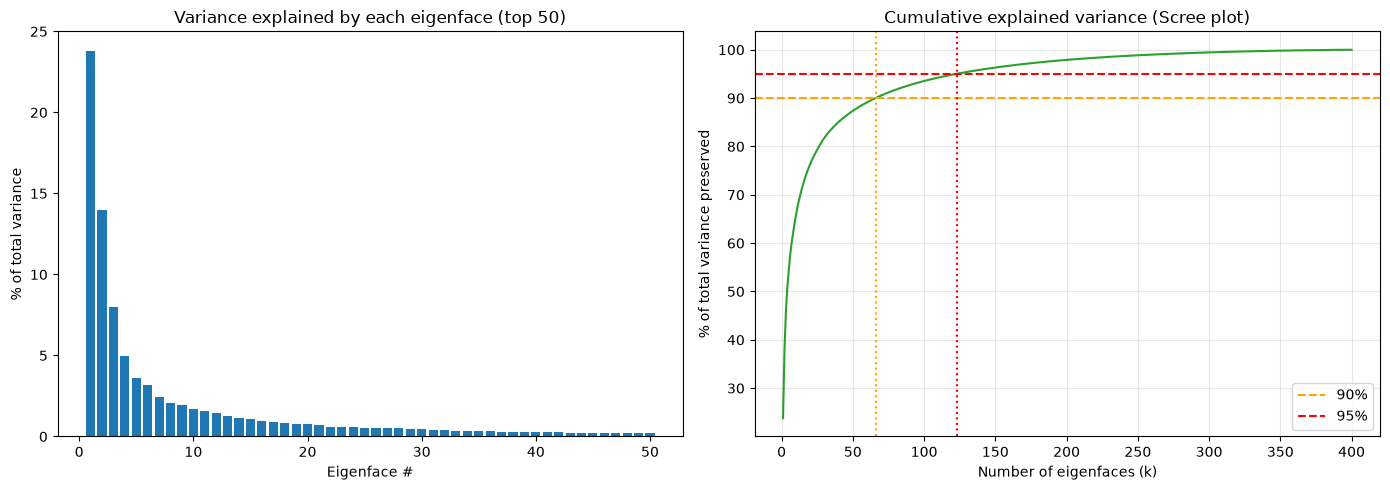

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Left: each slice of the pizza (top 50)
ax[0].bar(range(1, 51), var_ratio[:50] * 100, color='tab:blue')
ax[0].set_title("Variance explained by each eigenface (top 50)")
ax[0].set_xlabel("Eigenface #")
ax[0].set_ylabel("% of total variance")

# Right: the running total (scree plot)
ax[1].plot(range(1, 401), cum_var * 100, color='tab:green')
ax[1].axhline(90, color='orange', linestyle='--', label='90%')
ax[1].axhline(95, color='red', linestyle='--', label='95%')
ax[1].axvline(k90, color='orange', linestyle=':')
ax[1].axvline(k95, color='red', linestyle=':')
ax[1].set_title("Cumulative explained variance (Scree plot)")
ax[1].set_xlabel("Number of eigenfaces (k)")
ax[1].set_ylabel("% of total variance preserved")
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Does it look good at k90 and k95?

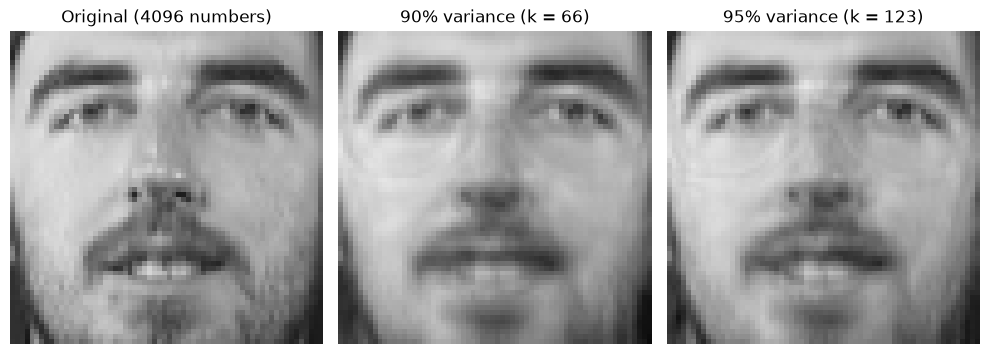

Relative squared error at k95: 0.0496
1 - cum_var[k95-1]:            0.0496


In [19]:
face_id = 100
fig, axes = plt.subplots(1, 3, figsize=(10, 4))
axes[0].imshow(X[face_id].reshape(64, 64), cmap='gray', vmin=0, vmax=1)
axes[0].set_title("Original (4096 numbers)")

for ax_i, (k, label) in zip([1, 2], [(k90, "90%"), (k95, "95%")]):
    _, rec = project_and_reconstruct(X_c[face_id:face_id+1], U, mu, k)
    axes[ax_i].imshow(rec.reshape(64, 64), cmap='gray', vmin=0, vmax=1)
    axes[ax_i].set_title(f"{label} variance (k = {k})")
for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()

# Check: fraction of variance LOST = relative squared error
_, X_rec_95 = project_and_reconstruct(X_c, U, mu, k95)
rel_err = np.sum((X - X_rec_95) ** 2) / np.sum(X_c ** 2)
print(f"Relative squared error at k95: {rel_err:.4f}")
print(f"1 - cum_var[k95-1]:            {1 - cum_var[k95 - 1]:.4f}")

# Mahalanobis Distance

## Build the latent codes and their statistics

In [20]:
k_latent = 20
Z20 = X_c @ U[:, :k_latent]                       # (400, 20) codes in face space

mu_z = Z20.mean(axis=0)                           # (20,) average code
Sigma_z = np.cov(Z20, rowvar=False, bias=True)    # (20, 20) covariance of codes

print("Z20 shape:", Z20.shape)
print("Sigma_z shape:", Sigma_z.shape)

# Checks
print("mu_z ≈ 0?", np.allclose(mu_z, 0, atol=1e-4))
print("Sigma_z is diagonal of eigenvalues?",
      np.allclose(Sigma_z, np.diag(lam[:k_latent]), atol=1e-6))

Z20 shape: (400, 20)
Sigma_z shape: (20, 20)
mu_z ≈ 0? True
Sigma_z is diagonal of eigenvalues? True


## The Mahalanobis function (pure NumPy)

In [21]:
def mahalanobis_sq(Z, mu_z, Sigma_inv):
    """Squared Mahalanobis distance of each row of Z from the latent mean."""
    diff = np.atleast_2d(Z) - mu_z                      # (n, k) differences
    return np.sum((diff @ Sigma_inv) * diff, axis=1)    # (n,) one score per face

Sigma_inv = np.linalg.inv(Sigma_z)                      # invert once, reuse many times
d2 = mahalanobis_sq(Z20, mu_z, Sigma_inv)
print("d² shape:", d2.shape)                            # (400,)

d² shape: (400,)


## Prove it works

In [22]:
# 1) Matches the diagonal shortcut: sum of z_i^2 / lambda_i
shortcut = np.sum((Z20 - mu_z) ** 2 / lam[:k_latent], axis=1)
print("Matches shortcut?", np.allclose(d2, shortcut))

# 2) With Sigma = Identity, Mahalanobis = plain Euclidean
euclid_sq = np.sum((Z20 - mu_z) ** 2, axis=1)
print("Identity gives Euclidean?",
      np.allclose(mahalanobis_sq(Z20, mu_z, np.eye(k_latent)), euclid_sq))

# 3) On the data we fit on, the average d² equals the number of dimensions
print("Mean d²:", d2.mean(), "(should be ≈ 20)")

Matches shortcut? True
Identity gives Euclidean? True
Mean d²: 20.0 (should be ≈ 20)


## Same “3 units away,” very different story

In [23]:
A = mu_z.copy(); A[0]  += 3      # 3 units along eigenface 1  (lots of normal wiggle)
B = mu_z.copy(); B[19] += 3      # 3 units along eigenface 20 (almost no normal wiggle)

for name, pt in [("A (direction 1)", A), ("B (direction 20)", B)]:
    eu = np.linalg.norm(pt - mu_z)
    ma = mahalanobis_sq(pt, mu_z, Sigma_inv)[0]
    print(f"{name}:  Euclidean = {eu:.2f}   Mahalanobis d² = {ma:.2f}")

A (direction 1):  Euclidean = 3.00   Mahalanobis d² = 0.48
B (direction 20):  Euclidean = 3.00   Mahalanobis d² = 15.27


## What do “normal” scores look like?

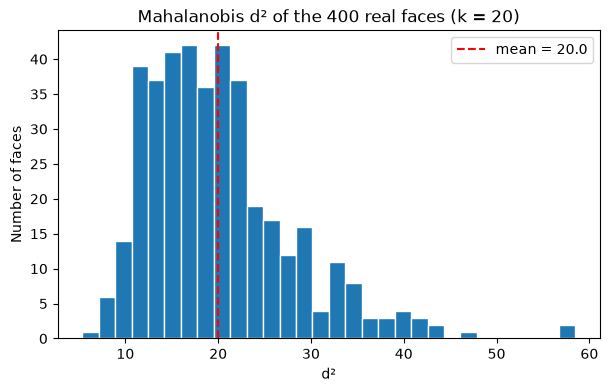

In [24]:
plt.figure(figsize=(7, 4))
plt.hist(d2, bins=30, color='tab:blue', edgecolor='white')
plt.axvline(d2.mean(), color='red', linestyle='--', label=f"mean = {d2.mean():.1f}")
plt.title("Mahalanobis d² of the 400 real faces (k = 20)")
plt.xlabel("d²")
plt.ylabel("Number of faces")
plt.legend()
plt.show()

# Outlier Gating, Test Setup

## Split and refit

In [25]:
# ---- 1) Split: per subject, photos 0-7 train, 8 val, 9 test ----
train_idx, val_idx, test_idx = [], [], []
for s in np.unique(subject_ids):
    idx = np.where(subject_ids == s)[0]
    train_idx += list(idx[:8]); val_idx.append(idx[8]); test_idx.append(idx[9])

X_train, X_val, X_test = X[train_idx], X[val_idx], X[test_idx]
print("Train / Val / Test:", X_train.shape, X_val.shape, X_test.shape)

# ---- 2) The whole eigenface pipeline in one function ----
def fit_eigenfaces(X_tr):
    n = X_tr.shape[0]
    mu = X_tr.mean(axis=0)
    Xc = (X_tr - mu).astype(np.float64)
    C = (Xc @ Xc.T) / n                          # snapshot matrix
    vals, vecs = np.linalg.eigh(C)
    order = np.argsort(vals)[::-1]
    vals, vecs = vals[order], vecs[:, order]
    keep = n - 1                                 # last eigenvalue is ~0
    U_raw = Xc.T @ vecs[:, :keep]                # map back to pixel space
    U = U_raw / np.linalg.norm(U_raw, axis=0)    # unit length
    return mu, U, np.clip(vals, 0, None)

def encode(X_in, mu, U, k):
    """Image(s) -> k-number code(s)."""
    return (np.atleast_2d(X_in) - mu) @ U[:, :k]

def fit_latent_gaussian(Z):
    return Z.mean(axis=0), np.cov(Z, rowvar=False, bias=True)

# ---- 3) Fit on TRAIN only ----
mu_tr, U_tr, lam_tr = fit_eigenfaces(X_train)
k = 20
Z_tr = encode(X_train, mu_tr, U_tr, k)
mu_z, Sigma_z = fit_latent_gaussian(Z_tr)
Sigma_inv = np.linalg.inv(Sigma_z)

print("U_tr shape:", U_tr.shape)    # (4096, 319)
print("Z_tr shape:", Z_tr.shape)    # (320, 20)

Train / Val / Test: (320, 4096) (40, 4096) (40, 4096)
U_tr shape: (4096, 319)
Z_tr shape: (320, 20)


## Build the test sets

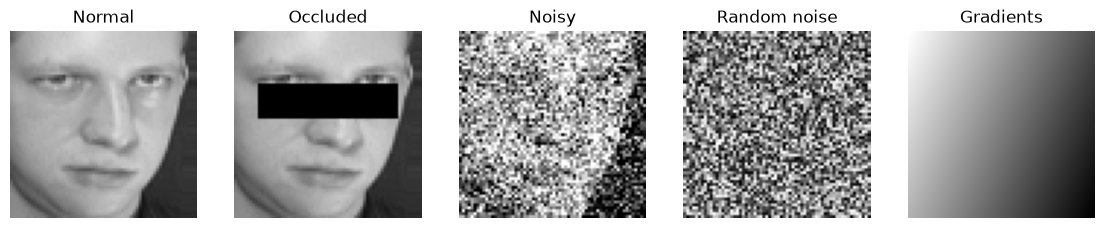

In [26]:
rng = np.random.default_rng(42)
n_test = X_test.shape[0]

# Occluded: black bar across the eyes
occluded = X_test.reshape(-1, 64, 64).copy()
occluded[:, 18:30, 8:56] = 0.0
occluded = occluded.reshape(-1, 4096)

# Noisy: add strong Gaussian static, keep pixels in [0, 1]
noisy = np.clip(X_test + rng.normal(0, 0.3, X_test.shape), 0, 1)

# Non-face 1: pure random static
random_noise = rng.uniform(0, 1, (n_test, 4096))

# Non-face 2: smooth gradients with random direction
yy, xx = np.mgrid[0:64, 0:64] / 63.0
angles = rng.uniform(0, 2 * np.pi, n_test)
grads = np.stack([np.cos(a) * xx + np.sin(a) * yy for a in angles])
gmin = grads.min(axis=(1, 2), keepdims=True)
gmax = grads.max(axis=(1, 2), keepdims=True)
gradients = ((grads - gmin) / (gmax - gmin)).reshape(-1, 4096)

test_sets = {
    "Normal":       X_test,
    "Occluded":     occluded,
    "Noisy":        noisy,
    "Random noise": random_noise,
    "Gradients":    gradients,
}

# Look at one example from each
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
for ax, (name, data) in zip(axes, test_sets.items()):
    ax.imshow(data[0].reshape(64, 64), cmap='gray', vmin=0, vmax=1)
    ax.set_title(name); ax.axis('off')
plt.show()

## Score everything with Mahalanobis

In [27]:
THRESH = 37.57

def gate1_score(X_in):
    return mahalanobis_sq(encode(X_in, mu_tr, U_tr, k), mu_z, Sigma_inv)

# How often do unseen REAL faces get falsely flagged? (validation set)
d2_val = gate1_score(X_val)
print(f"Validation faces flagged: {np.mean(d2_val > THRESH)*100:.1f}%")

# Score all five test sets
scores = {name: gate1_score(data) for name, data in test_sets.items()}

print(f"\n{'Category':<14}{'median d²':>12}{'max d²':>12}{'flagged as anomaly':>22}")
for name, d in scores.items():
    print(f"{name:<14}{np.median(d):>12.1f}{d.max():>12.1f}{np.mean(d > THRESH)*100:>21.0f}%")

Validation faces flagged: 5.0%

Category         median d²      max d²    flagged as anomaly
Normal                16.6        32.4                    0%
Occluded              97.4       143.3                  100%
Noisy                 13.4        30.7                    0%
Random noise          12.6        15.6                    0%
Gradients             45.4        91.7                   82%


## Picture it

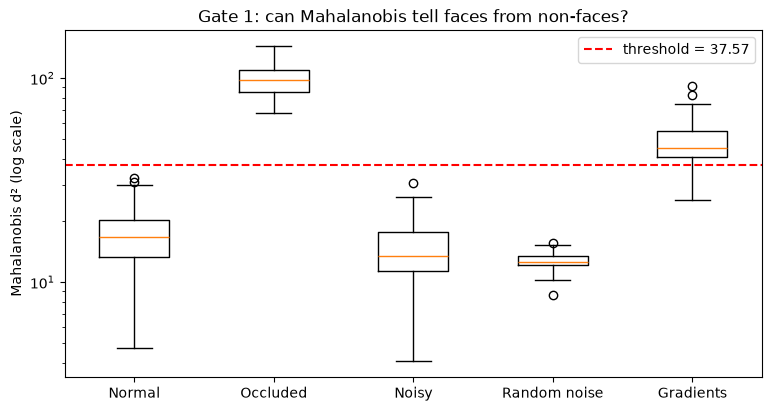

In [28]:
fig, ax = plt.subplots(figsize=(9, 4.5))
names = list(scores.keys())
ax.boxplot([scores[n] for n in names])
ax.set_xticks(range(1, len(names) + 1))
ax.set_xticklabels(names)
ax.axhline(THRESH, color='red', linestyle='--', label=f"threshold = {THRESH}")
ax.set_yscale('log')
ax.set_ylabel("Mahalanobis d² (log scale)")
ax.set_title("Gate 1: can Mahalanobis tell faces from non-faces?")
ax.legend()
plt.show()

# The Second Gate

## Gate 2 score

The Pythagoras bonus 📐

Each centered image splits into two perpendicular parts: the part inside face space (its code) and the leftover. So:
```
‖x_c‖²  =  ‖z‖²  +  ‖leftover‖²      →      leftover² = ‖x_c‖² − ‖z‖²
```
We’ll verify this, which proves the eigenfaces are truly orthonormal.

In [29]:
def gate2_score(X_in):
    """Mean squared leftover per pixel after rebuilding from k eigenfaces."""
    Xc_in = np.atleast_2d(X_in) - mu_tr
    Uk = U_tr[:, :k]
    recon = (Xc_in @ Uk) @ Uk.T            # rebuild (no mean added: we compare centered)
    return np.mean((Xc_in - recon) ** 2, axis=1)

# Pythagoras check: leftover = (total energy - code energy) / 4096
Xc_t = X_test - mu_tr
Z_t = encode(X_test, mu_tr, U_tr, k)
pyth = (np.sum(Xc_t ** 2, axis=1) - np.sum(Z_t ** 2, axis=1)) / 4096
print("Pythagoras holds?", np.allclose(gate2_score(X_test), pyth))

Pythagoras holds? True


## Pick the Gate 2 threshold (using validation faces only!)

In [30]:
res_val = gate2_score(X_val)
RES_THRESH = res_val.mean() + 3 * res_val.std()

print(f"Real-face leftover (val): mean = {res_val.mean():.4f}, max = {res_val.max():.4f}")
print(f"Gate 2 threshold:         {RES_THRESH:.4f}")

Real-face leftover (val): mean = 0.0055, max = 0.0105
Gate 2 threshold:         0.0119


## The two-gate classifier and the results

In [31]:
def classify(X_in):
    d2  = gate1_score(X_in)
    res = gate2_score(X_in)
    ok  = (d2 <= THRESH) & (res <= RES_THRESH)       # must pass BOTH gates
    labels = np.where(ok, "Valid Face", "Anomaly")
    return labels, d2, res

print(f"{'Category':<14}{'median res':>12}{'Gate1 flags':>13}{'Gate2 flags':>13}{'FINAL: Anomaly':>16}")
results = {}
for name, data in test_sets.items():
    labels, d2, res = classify(data)
    results[name] = (labels, d2, res)
    g1 = np.mean(d2 > THRESH) * 100
    g2 = np.mean(res > RES_THRESH) * 100
    fin = np.mean(labels == "Anomaly") * 100
    print(f"{name:<14}{np.median(res):>12.4f}{g1:>12.0f}%{g2:>12.0f}%{fin:>15.0f}%")

Category        median res  Gate1 flags  Gate2 flags  FINAL: Anomaly
Normal              0.0049           0%           0%              0%
Occluded            0.0321         100%         100%            100%
Noisy               0.0718           0%         100%            100%
Random noise        0.0847           0%         100%            100%
Gradients           0.0064          82%           0%             82%


## See the two gates together

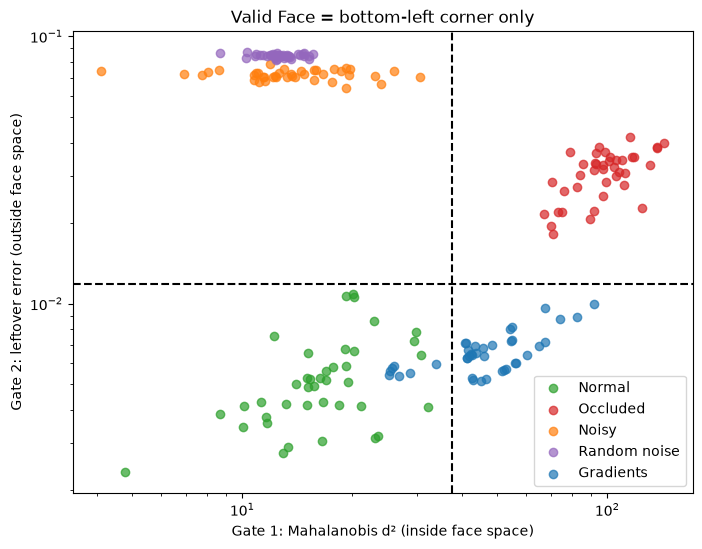

In [32]:
fig, ax = plt.subplots(figsize=(8, 6))
colors = {"Normal": "tab:green", "Occluded": "tab:red", "Noisy": "tab:orange",
          "Random noise": "tab:purple", "Gradients": "tab:blue"}
for name, (labels, d2, res) in results.items():
    ax.scatter(d2, res, label=name, color=colors[name], alpha=0.7)
ax.axvline(THRESH, color='k', linestyle='--')
ax.axhline(RES_THRESH, color='k', linestyle='--')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel("Gate 1: Mahalanobis d² (inside face space)")
ax.set_ylabel("Gate 2: leftover error (outside face space)")
ax.set_title("Valid Face = bottom-left corner only")
ax.legend()
plt.show()

## One final report card

In [33]:
# Truth: Normal = 0 (face), everything else = 1 (anomaly)
y_true, y_pred = [], []
for name, (labels, _, _) in results.items():
    y_true += [0 if name == "Normal" else 1] * len(labels)
    y_pred += list((labels == "Anomaly").astype(int))
y_true, y_pred = np.array(y_true), np.array(y_pred)

TP = np.sum((y_true == 1) & (y_pred == 1))   # anomalies caught
FN = np.sum((y_true == 1) & (y_pred == 0))   # anomalies that slipped through
FP = np.sum((y_true == 0) & (y_pred == 1))   # good faces wrongly flagged
TN = np.sum((y_true == 0) & (y_pred == 0))   # good faces accepted

print(f"Anomalies caught:     {TP}/{TP+FN}  ({TP/(TP+FN)*100:.1f}%)")
print(f"Real faces accepted:  {TN}/{TN+FP}  ({TN/(TN+FP)*100:.1f}%)")
print(f"Overall accuracy:     {(TP+TN)/len(y_true)*100:.1f}%")

Anomalies caught:     153/160  (95.6%)
Real faces accepted:  40/40  (100.0%)
Overall accuracy:     96.5%


# SQLite Telemetry Database

## Create the database and tables

In [34]:
import sqlite3

DB_PATH = "eigen_telemetry.db"
conn = sqlite3.connect(DB_PATH)
cur = conn.cursor()

# Start fresh so you can re-run this cell safely
cur.execute("DROP TABLE IF EXISTS rank_evaluations")
cur.execute("DROP TABLE IF EXISTS image_metadata")

cur.execute("""
CREATE TABLE image_metadata (
    image_id    INTEGER PRIMARY KEY,
    subject_id  INTEGER NOT NULL,
    photo_index INTEGER NOT NULL
)
""")

cur.execute("""
CREATE TABLE rank_evaluations (
    eval_id        INTEGER PRIMARY KEY AUTOINCREMENT,
    image_id       INTEGER NOT NULL REFERENCES image_metadata(image_id),
    rank_k         INTEGER NOT NULL,
    mse            REAL    NOT NULL,
    frobenius      REAL    NOT NULL,
    mahalanobis_d2 REAL    NOT NULL,
    loss_pct       REAL    NOT NULL
)
""")
conn.commit()
print("Tables created.")

Tables created.


## Fill image_metadata

In [35]:
# photo_index = which photo (0-9) of that person this is
photo_index = np.zeros(400, dtype=int)
for s in np.unique(subject_ids):
    idx = np.where(subject_ids == s)[0]
    photo_index[idx] = np.arange(len(idx))

meta_rows = [(int(i), int(subject_ids[i]), int(photo_index[i])) for i in range(400)]
cur.executemany("INSERT INTO image_metadata VALUES (?, ?, ?)", meta_rows)
conn.commit()
print("image_metadata rows:", len(meta_rows))     # 400

image_metadata rows: 400


## Fill rank_evaluations

In [36]:
eval_ranks = [5, 10, 15, 20, 30, 40, 60, 80, 100, 150]

Z_full = X_c @ U                                  # (400, 399) all codes at once
energy = np.sum(X_c ** 2, axis=1)                 # ||x_c||^2 per image

eval_rows = []
for r in eval_ranks:
    Zr = Z_full[:, :r]
    X_rec_r = Zr @ U[:, :r].T + mu                # rebuild with r eigenfaces
    diff = X - X_rec_r

    mse   = np.mean(diff ** 2, axis=1)            # per image
    frob  = np.linalg.norm(diff, axis=1)
    d2_r  = np.sum(Zr ** 2 / lam[:r], axis=1)     # Mahalanobis with r components
    loss  = 100 * np.sum(diff ** 2, axis=1) / energy

    for i in range(400):
        eval_rows.append((int(i), int(r), float(mse[i]), float(frob[i]),
                          float(d2_r[i]), float(loss[i])))

cur.executemany("""
INSERT INTO rank_evaluations (image_id, rank_k, mse, frobenius, mahalanobis_d2, loss_pct)
VALUES (?, ?, ?, ?, ?, ?)
""", eval_rows)
conn.commit()
print("rank_evaluations rows:", len(eval_rows))   # 4000

rank_evaluations rows: 4000


## Check that the database tells the truth

In [37]:
# 1) Row counts
print("images:", cur.execute("SELECT COUNT(*) FROM image_metadata").fetchone()[0])
print("evals: ", cur.execute("SELECT COUNT(*) FROM rank_evaluations").fetchone()[0])

# 2) Average error per rank. Should match Part 4's table
print(f"\n{'k':>5}{'avg MSE':>12}{'avg loss %':>13}{'avg d²':>10}")
for k_, m, l, d in cur.execute("""
    SELECT rank_k, AVG(mse), AVG(loss_pct), AVG(mahalanobis_d2)
    FROM rank_evaluations
    GROUP BY rank_k
    ORDER BY rank_k
"""):
    print(f"{k_:>5}{m:>12.6f}{l:>13.2f}{d:>10.2f}")

# 3) A first JOIN: which people are in the table, and how many rows each?
print("\nRows for subject 0:", cur.execute("""
    SELECT COUNT(*)
    FROM rank_evaluations e
    JOIN image_metadata m ON m.image_id = e.image_id
    WHERE m.subject_id = 0
""").fetchone()[0])                                # 10 images x 10 ranks = 100

images: 400
evals:  4000

    k     avg MSE   avg loss %    avg d²
    5    0.008789        50.56      5.00
   10    0.006622        37.98     10.00
   15    0.005371        30.62     15.00
   20    0.004559        26.17     20.00
   30    0.003509        20.26     30.00
   40    0.002877        16.71     40.00
   60    0.002093        12.17     60.00
   80    0.001594         9.36     80.00
  100    0.001246         7.36    100.00
  150    0.000709         4.29    150.00

Rows for subject 0: 100


# Some SQL Queries

## Running 8 queries from Python

In [38]:
# (If you restarted the notebook, reconnect first:)
# conn = sqlite3.connect("eigen_telemetry.db"); cur = conn.cursor()

with open("queries.sql", "r", encoding="utf-8") as f:
    chunks = [c.strip() for c in f.read().split(";") if c.strip()]

print("Number of queries found:", len(chunks))     # should be 8

for chunk in chunks:
    title = chunk.splitlines()[0]                  # the "-- Qn ..." line
    cur.execute(chunk)
    cols = [d[0] for d in cur.description]
    rows = cur.fetchall()

    print("\n" + title)
    print(" | ".join(cols))
    for row in rows[:8]:
        print(" | ".join(str(v) for v in row))
    if len(rows) > 8:
        print(f"... ({len(rows)} rows total)")

Number of queries found: 8

-- Q1. Summary per rank: how does quality improve as k grows
rank_k | avg_mse | avg_loss_pct | best_case_loss | worst_case_loss
5 | 0.008789 | 50.56 | 12.15 | 98.46
10 | 0.006622 | 37.98 | 9.45 | 85.92
15 | 0.005371 | 30.62 | 9.03 | 62.24
20 | 0.004559 | 26.17 | 7.61 | 58.77
30 | 0.003509 | 20.26 | 6.67 | 47.66
40 | 0.002877 | 16.71 | 5.2 | 39.86
60 | 0.002093 | 12.17 | 3.37 | 29.1
80 | 0.001594 | 9.36 | 2.75 | 23.95
... (10 rows total)

-- Q2. Hardest people to rebuild at k = 30 (AVG + HAVING, 25 percent worse than average)
subject_id | avg_loss_pct | n_photos
12 | 33.0 | 10
3 | 30.9 | 10
13 | 28.01 | 10
26 | 27.28 | 10
14 | 26.41 | 10
20 | 26.19 | 10
19 | 26.16 | 10
1 | 25.72 | 10
... (9 rows total)

-- Q3. Quality buckets: Lossy (20 percent loss or more), Standard (5 to 20), Near-Lossless (under 5)
rank_k | lossy | standard | near_lossless
5 | 385 | 15 | 0
10 | 368 | 32 | 0
15 | 340 | 60 | 0
20 | 287 | 113 | 0
30 | 189 | 211 | 0
40 | 102 | 298 | 0
60 | 29

# results summary

In [39]:
print("=== KEY RESULTS ===")
print(f"Snapshot matrix: {C.shape}  (vs 4096 x 4096)")
print(f"k for 90% / 95% / 99% variance: {k90} / {k95} / {k99}")
print(f"Gate 1 threshold (d²): {THRESH}   Gate 2 threshold: {RES_THRESH:.4f}")
print(f"Anomalies caught: {TP}/{TP+FN}   Real faces accepted: {TN}/{TN+FP}")
print(f"Overall accuracy: {(TP+TN)/len(y_true)*100:.1f}%")

conn.close()     # close the database when you're done

=== KEY RESULTS ===
Snapshot matrix: (400, 400)  (vs 4096 x 4096)
k for 90% / 95% / 99% variance: 66 / 123 / 260
Gate 1 threshold (d²): 37.57   Gate 2 threshold: 0.0119
Anomalies caught: 153/160   Real faces accepted: 40/40
Overall accuracy: 96.5%


making the app independent of my laptop

In [40]:
np.savez_compressed("olivetti_faces.npz", X=X.astype(np.float32), subject_ids=subject_ids)

import os
print("Saved:", os.path.getsize("olivetti_faces.npz") / 1e6, "MB")   # a few MB, fine for GitHub

Saved: 1.804041 MB
